# Explore a Wi-Fi Doppler spectrogram

This example uses walking (`W`), session `S1a`, antenna stream `0`. Each row stores power across 100 Doppler bins at one time step. Colors show power, not body position. The horizontal axis in the heatmaps is time: we transpose the array only for plotting.

Time is approximate, using the paper's 6 ms interval. Bin indices are retained because these files contain no explicit velocity coordinates. This is already processed Doppler data, not the original Wi-Fi waveform.

In [1]:
from pathlib import Path
import pickle
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path('/home/ubuntu/Deep Learning')
# Change the filename to explore another activity or antenna.
filename = 'S1a_W_stream_0.txt'
matches = sorted(ROOT.joinpath('Data').rglob(filename))
if not matches:
    raise FileNotFoundError(filename)
trace_path = matches[0]

# The supplied .txt files are binary NumPy pickles, not text.
# Only allow the NumPy types used by these dataset files.
class NumpyArrayReader(pickle.Unpickler):
    def find_class(self, module, name):
        allowed = {
            ('numpy', 'ndarray'): np.ndarray,
            ('numpy', 'dtype'): np.dtype,
            ('numpy.core.multiarray', '_reconstruct'): np._core.multiarray._reconstruct,
            ('numpy._core.multiarray', '_reconstruct'): np._core.multiarray._reconstruct,
        }
        if (module, name) not in allowed:
            raise ValueError(f'Unexpected serialized type: {module}.{name}')
        return allowed[module, name]

with trace_path.open('rb') as f:
    data = NumpyArrayReader(f).load()
assert isinstance(data, np.ndarray) and data.ndim == 2 and data.shape[1] == 100
assert np.isfinite(data).all() and (data >= 0).all()
print('File:', trace_path)
print('Shape (time steps, Doppler bins):', data.shape)
print('Range:', data.min(), 'to', data.max())
print('First 5 rows and 8 bins:')
print(data[:5, :8])


File: /home/ubuntu/Deep Learning/Data/drive-download-20260811T182648Z-1-001/doppler_traces/S1a/S1a_W_stream_0.txt
Shape (time steps, Doppler bins): (19295, 100)
Range: 0.06309573444801933 to 1.0
First 5 rows and 8 bins:
[[0.06309573 0.06309573 0.06309573 0.06309573 0.06309573 0.06309573
  0.06309573 0.06309573]
 [0.06309573 0.06309573 0.06309573 0.06309573 0.06309573 0.06309573
  0.06309573 0.06309573]
 [0.06309573 0.06309573 0.06309573 0.06309573 0.06309573 0.06309573
  0.06309573 0.06309573]
 [0.06309573 0.06309573 0.06309573 0.06309573 0.06309573 0.06309573
  0.06309573 0.06309573]
 [0.06309573 0.06309573 0.06309573 0.06309573 0.06309573 0.06309573
  0.06309573 0.06309573]]


## Three views of the same data

Change `START_SECONDS` and `SNAPSHOT_ROW`, then rerun the next cell. The third plot is one matrix row: a power distribution over Doppler bins, **not** a waveform over time. Dark colors are weak contributions; bright colors are strong ones. After frequency centering, zero Doppler is near the middle bin. The displayed color range is −12 to 0 dB, consistent with the inspected normalized power floor. No data is resized.

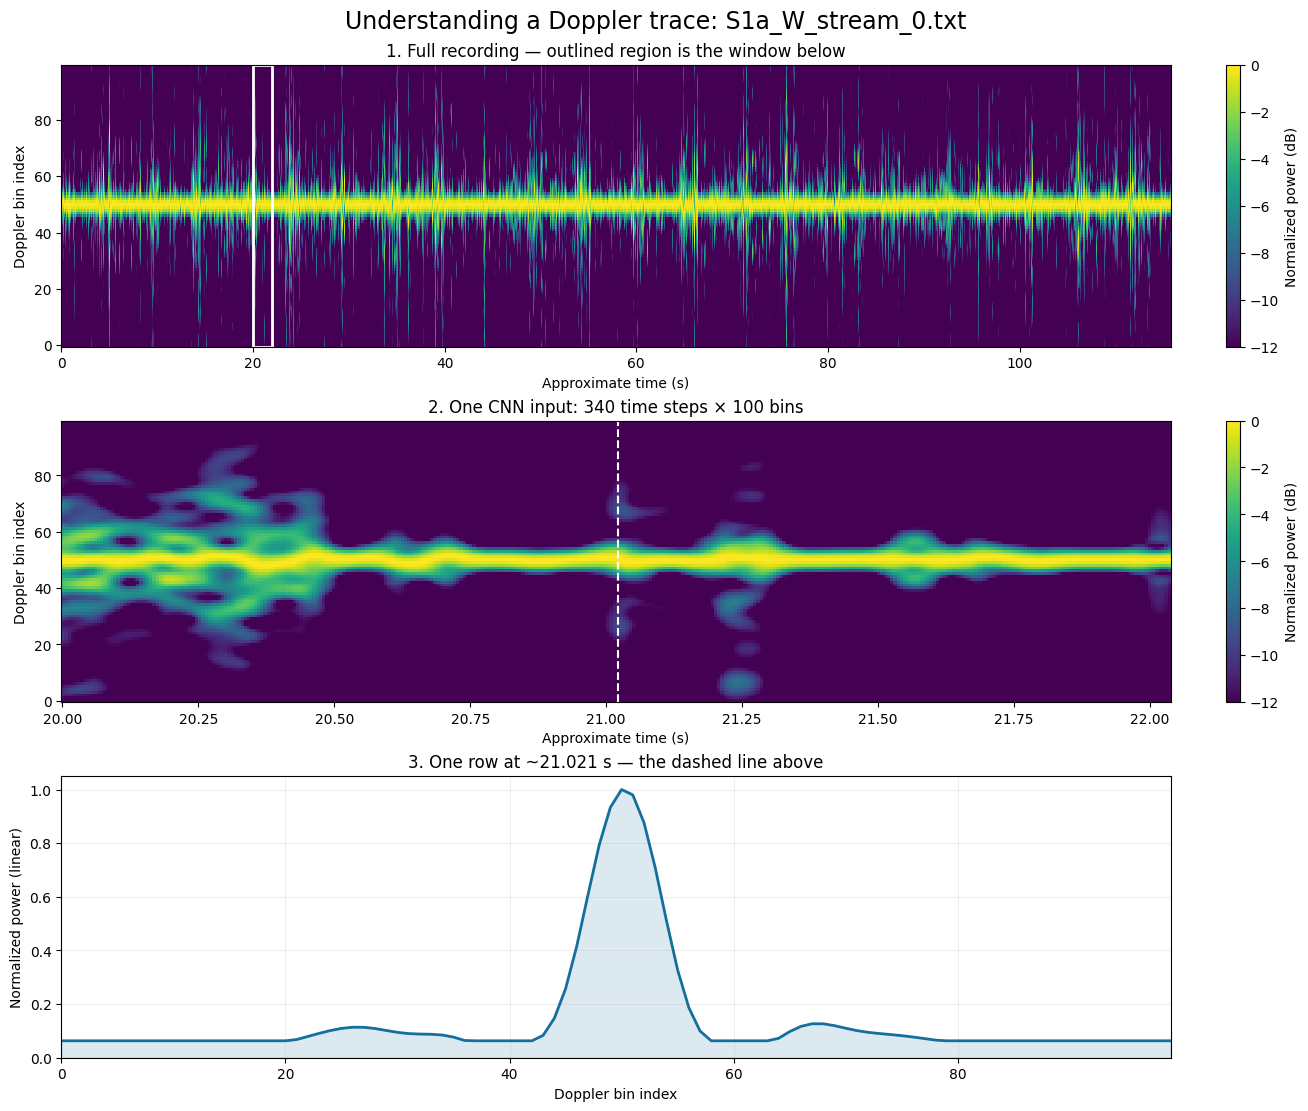

Saved: /home/ubuntu/Deep Learning/Report/doppler_exploration.png
CNN input shape: (1, 340, 100)


In [2]:
# Approximate sampling interval from the SHARP paper, not measured timestamps.
DT = 0.006
START_SECONDS = 20.0       # Change this to inspect another part of the recording.
WINDOW_ROWS = 340         # One CNN example (~2 seconds).
SNAPSHOT_ROW = 170        # Time step inside that example; range 0..339.

start = int(round(START_SECONDS / DT))
if not 0 <= start <= len(data) - WINDOW_ROWS:
    raise ValueError('Choose a start time with at least 340 rows remaining.')
if not 0 <= SNAPSHOT_ROW < WINDOW_ROWS:
    raise ValueError('SNAPSHOT_ROW must be between 0 and 339.')
window = data[start:start + WINDOW_ROWS]
# Power ratio -> decibels. This is for visualization, not a training decision.
db = 10 * np.log10(np.maximum(data, np.finfo(float).tiny))
window_db = db[start:start + WINDOW_ROWS]
bin_ids = np.arange(100)
end = (start + WINDOW_ROWS) * DT
selected_t = (start + SNAPSHOT_ROW + 0.5) * DT

fig, axes = plt.subplots(3, 1, figsize=(13, 11), constrained_layout=True)
fig.suptitle(f'Understanding a Doppler trace: {filename}', fontsize=17)
image_options = dict(origin='lower', aspect='auto', cmap='viridis',
                     vmin=-12, vmax=0, interpolation='nearest')
im = axes[0].imshow(db.T, extent=[0, len(data)*DT, -0.5, 99.5], **image_options)
axes[0].axvspan(start*DT, end, facecolor='none', edgecolor='white', linewidth=2)
axes[0].set(title='1. Full recording — outlined region is the window below',
            xlabel='Approximate time (s)', ylabel='Doppler bin index')
fig.colorbar(im, ax=axes[0], label='Normalized power (dB)')
im = axes[1].imshow(window_db.T, extent=[start*DT, end, -0.5, 99.5], **image_options)
axes[1].axvline(selected_t, color='white', linestyle='--', linewidth=1.5)
axes[1].set(title='2. One CNN input: 340 time steps × 100 bins',
            xlabel='Approximate time (s)', ylabel='Doppler bin index')
fig.colorbar(im, ax=axes[1], label='Normalized power (dB)')
axes[2].plot(bin_ids, window[SNAPSHOT_ROW], color='#156f9c', linewidth=2)
axes[2].fill_between(bin_ids, window[SNAPSHOT_ROW], color='#156f9c', alpha=0.15)
axes[2].set(title=f'3. One row at ~{selected_t:.3f} s — the dashed line above',
            xlabel='Doppler bin index', ylabel='Normalized power (linear)',
            xlim=(0,99), ylim=(0,1.05))
axes[2].grid(alpha=0.2)
out = ROOT / 'Results' / 'doppler_exploration.png'
out.parent.mkdir(exist_ok=True)
fig.savefig(out, dpi=160)
plt.show()
print('Saved:', out)
print('CNN input shape:', window[np.newaxis, ...].shape)
